## Machine Learning CA1

### CCT HDIP Data Analytics September 2026

##### Student: Jing Liang

This project applies machine learning to classify foetal state from cardiotocography (CTG) data. The original dataset, obtained from the UCI Machine Learning Repository, contains 2,126 CTG segments. After data cleaning, 2,111 observations and 21 predictor features were used for modelling. Each segment was classified as Normal, Suspect or Pathologic (NSP).

The project addresses two questions:

1. Which model, Decision Tree or Random Forest, performs better in classifying foetal state?
2. Which CTG features are most important for this classification?


## 0. Import Libraries

In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

## 1. Data Preparation

#### 1.1 Load the dataset

The original data was provided as an Excel file containing three sheets: Description, Data and Raw Data. The raw data sheet was re-saved in .csv format as "CTG_raw_data.csv".

In [2]:
df_original = pd.read_csv('CTG_raw_data.csv')

#### 1.2 Initial data inspection

In [3]:
df_original.head(5)

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Variab10.txt,01/12/1996,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
2,Fmcs_1.txt,03/05/1996,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,03/05/1996,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,03/05/1996,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0


In [4]:
df_original.tail(5)

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
2125,S8001045.dsp,06/06/1998,CTG2127.txt,1576.0,3049.0,140.0,140.0,1.0,0.0,9.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,5.0,2.0
2126,S8001045.dsp,06/06/1998,CTG2128.txt,2796.0,3415.0,142.0,142.0,1.0,1.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
2127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2129,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,564.0,23.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_original.shape

(2130, 40)

In [6]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 2130 entries, 0 to 2129
Data columns (total 40 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   FileName  2126 non-null   str    
 1   Date      2126 non-null   str    
 2   SegFile   2126 non-null   str    
 3   b         2126 non-null   float64
 4   e         2126 non-null   float64
 5   LBE       2126 non-null   float64
 6   LB        2126 non-null   float64
 7   AC        2126 non-null   float64
 8   FM        2127 non-null   float64
 9   UC        2127 non-null   float64
 10  ASTV      2127 non-null   float64
 11  MSTV      2127 non-null   float64
 12  ALTV      2127 non-null   float64
 13  MLTV      2127 non-null   float64
 14  DL        2128 non-null   float64
 15  DS        2128 non-null   float64
 16  DP        2128 non-null   float64
 17  DR        2128 non-null   float64
 18  Width     2126 non-null   float64
 19  Min       2126 non-null   float64
 20  Max       2126 non-null   float64
 21  Nm

#### 1.3 Remove non-data rows

In [7]:
# Copy the dataset

df = df_original.copy()

In [8]:
# Drop blank and summary rows

df = df.dropna(subset=['NSP'])

In [9]:
df.shape

(2126, 40)

#### 1.4 Inspect the target variable and the recording structure

In [10]:
# Check the structure of the target column

df['NSP'].value_counts()

NSP
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64

According to the Description: Normal=1; Suspect=2; Pathologic=3. The NSP results are imbalanced.

In [11]:
# Check the number of original CTG recordings

df['FileName'].value_counts()

FileName
S8001034.dsp    34
S7001029.dsp    33
S8001037.dsp    30
S8001038.dsp    26
S7001027.dsp    24
                ..
Mmbms_16.txt     1
S0001055.dat     1
S7001006.dsp     1
S7001008.dsp     1
S7001021.dsp     1
Name: count, Length: 352, dtype: int64

Although this dataset contains 2126 measurements, they come from only 352 recordings. The number of segments per recording ranges from 1 to 34.

#### 1.5 Select predictor variables and target

As marked in Description: DR is removed since p(K-W)=1, check the reason:

In [12]:
df['DR'].value_counts()

DR
0.0    2126
Name: count, dtype: int64

In [13]:
df['DR'].nunique()

1

Of the 40 columns, only the 21 features highlighted in the Description sheet will be kept as predictors. NSP is selected as the target variable for a 3-class classification of foetal state. As mentioned in the UCI repository (UCI, n.d.), the morphologic pattern columns (A to SUSP) and CLASS will be removed to avoid data leakage, as they are a second set of expert labels. In addition, the following columns will be removed as well: columns irrelevant to foetal state, such as FileName, Date, SegFile, b and e, the duplicate column LBE (identical to LB), and DR, which contains only zeros.


In [14]:
features = [
    'LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'Width', 'Min', 
    'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency'
]

#### 1.6 Convert event counts to rates

The variables AC (accelerations), FM (foetal movements), UC (uterine contractions), DL (light decelerations), DS (severe decelerations) and DP (prolonged decelerations) recorded the total number of events in each segment, from b (start instant) to e (end instant). As the length of each segment varies, each count will be divided by the segment duration to make the variables comparable.

In [15]:
# Segment length in seconds

(df['e']-df['b']).describe()

count    2126.000000
mean      824.437441
std       305.054024
min       117.000000
25%       613.000000
50%       799.000000
75%      1041.000000
max      3599.000000
dtype: float64

In [16]:
df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP']].head(3)

,b,e,AC,FM,UC,DL,DS,DP
1,240.0,357.0,0.0,0.0,0.0,0.0,0.0,0.0
2,5.0,632.0,4.0,0.0,4.0,2.0,0.0,0.0
3,177.0,779.0,2.0,0.0,5.0,2.0,0.0,0.0


In [17]:
# Convert counts to rates per second

for col in ['AC', 'FM', 'UC', 'DL', 'DS', 'DP']:
    df[col] = df[col] / (df['e']-df['b'])

In [18]:
df[['b', 'e', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP']].head(3)

,b,e,AC,FM,UC,DL,DS,DP
1,240.0,357.0,0.000000,0.0,0.000000,0.000000,0.0,0.0
2,5.0,632.0,0.006380,0.0,0.006380,0.003190,0.0,0.0
3,177.0,779.0,0.003322,0.0,0.008306,0.003322,0.0,0.0


#### 1.7 Checking missing values and duplicate records

In [19]:
# Check missing values

df.isnull().sum()

FileName    0
Date        0
SegFile     0
b           0
e           0
LBE         0
LB          0
AC          0
FM          0
UC          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
DL          0
DS          0
DP          0
DR          0
Width       0
Min         0
Max         0
Nmax        0
Nzeros      0
Mode        0
Mean        0
Median      0
Variance    0
Tendency    0
A           0
B           0
C           0
D           0
E           0
AD          0
DE          0
LD          0
FS          0
SUSP        0
CLASS       0
NSP         0
dtype: int64

In [20]:
df.shape

(2126, 40)

In [21]:
# Check duplicated records

duplicate_cols = ['FileName', 'b', 'e'] + features + ['NSP']

duplicates = df[df.duplicated(subset=duplicate_cols, keep=False)]

duplicates

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
68,S0001090_1.dat,02/05/1996,CTG0068.txt,10.0,697.0,140.0,140.0,0.007278,0.000000,0.004367,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0
69,S0001090_1.dat,02/05/1996,CTG0069.txt,10.0,697.0,140.0,140.0,0.007278,0.000000,0.004367,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0
230,Aast_10.txt,06/05/1996,CTG0230.txt,0.0,1199.0,123.0,123.0,0.002502,0.003336,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0
234,Aast_10.txt,06/05/1996,CTG0234.txt,276.0,596.0,123.0,123.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
235,Aast_10.txt,06/05/1996,CTG0235.txt,276.0,596.0,123.0,123.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
324,Mabp_4.txt,02/05/1996,CTG0324.txt,179.0,666.0,135.0,135.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,3.0
325,Mabp_4.txt,02/05/1996,CTG0325.txt,179.0,666.0,135.0,135.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,3.0
327,Mabp_6.txt,02/05/1996,CTG0327.txt,0.0,809.0,144.0,144.0,0.000000,0.018541,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,10.0,2.0
334,Mabp_6.txt,02/05/1996,CTG0334.txt,0.0,809.0,144.0,144.0,0.000000,0.018541,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,10.0,2.0
788,Aast_10.txt,06/05/1996,CTG0788.txt,0.0,1199.0,123.0,123.0,0.002502,0.003336,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0


In [22]:
print(df.duplicated(subset=duplicate_cols).sum())

11


In [23]:
# Drop the duplicated rows

df = df.drop_duplicates(subset=duplicate_cols, keep='first')

In [24]:
df.shape

(2115, 40)

In [25]:
df.duplicated(subset=duplicate_cols).sum()

np.int64(0)

11 exact duplicate records were removed, reducing the dataset from 2,126 to 2,115 observations.

#### 1.8 Check conflicting labels

Conflicting rows are the ones with the same FileName, time window and 21 features but different NSP values. Since exact duplicates were already removed, repeating the duplicate check without NSP identifies these rows. They will be removed because the correct label cannot be determined.

In [26]:
conflict_cols = ['FileName', 'b', 'e'] + features

conflicts = df[df.duplicated(subset=conflict_cols, keep=False)]

conflicts[['FileName', 'SegFile', 'b', 'e', 'NSP']]

,FileName,SegFile,b,e,NSP
807,S0001011.dat,CTG0807.txt,70.0,928.0,1.0
808,S0001011.dat,CTG0808.txt,70.0,928.0,2.0
1381,S0001085.dat,CTG1383.txt,1925.0,2500.0,2.0
1382,S0001085.dat,CTG1384.txt,1925.0,2500.0,1.0


In [27]:
# Drop conflict rows

df = df.drop(conflicts.index)

In [28]:
df.shape

(2111, 40)

Two conflicting groups (4 rows) with conflicting NSP labels were identified and removed, leaving 2,111 rows.

#### 1.9 Create the final modelling dataset

In [29]:
# Final cleaned dataset: 21 features + target

df_clean = df[features + ['NSP']].copy()
df_clean['NSP'] = df_clean['NSP'].astype(int)

In [30]:
# Export the cleaned dataset

df_clean.to_csv('CTG_clean.csv', index=False)

In [139]:
# Split into features (x) and target (y) for modelling

X = df_clean[features]
y = df_clean['NSP']

In [32]:
df_clean.shape

(2111, 22)

## 2. Exploratory Data Analysis

#### 2.1 Target class distribution

In [51]:
NSP_class_counts = y.value_counts().sort_index()

NSP_class_counts

NSP
1    1645
2     291
3     175
Name: count, dtype: int64

In [52]:
NSP_class_percentages = y.value_counts(normalize=True).sort_index() * 100

NSP_class_percentages

NSP
1    77.925154
2    13.784936
3     8.289910
Name: proportion, dtype: float64

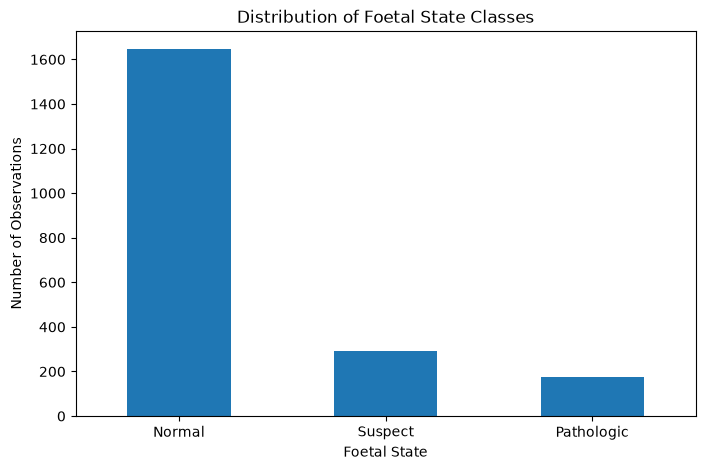

In [46]:
NSP_class_labels = ['Normal', 'Suspect', 'Pathologic']

NSP_class_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Distribution of Foetal State Classes')
plt.xlabel('Foetal State')
plt.ylabel('Number of Observations')
plt.xticks(
    ticks=[0, 1, 2],
    labels=NSP_class_labels,
    rotation=0
)
plt.show()

The target variable is imbalanced, with 77.9% of observations classified as Normal. A model that always predicts Normal would achieve about 78% accuracy, accuracy alone can be misleading. Therefore, recall and F1 scores should also be examined for each class, particularly the Pathologic class. Stratified splitting is needed to maintain similar class proportions across subsets, especially when the test set contains only 5% of the data.

#### 2.2 Predictor variables summary and distributions

In [58]:
# Summary statistics of the 21 features

df_clean[features].describe().T

,count,mean,std,min,25%,50%,75%,max
LB,2111.0,133.312174,9.830875,106.0,126.000000,133.000000,140.000000,160.000000
AC,2111.0,0.003184,0.003865,0.0,0.000000,0.001658,0.005650,0.019284
FM,2111.0,0.009529,0.046829,0.0,0.000000,0.000000,0.002527,0.480634
UC,2111.0,0.004379,0.002936,0.0,0.001928,0.004517,0.006536,0.014925
DL,2111.0,0.001893,0.002967,0.0,0.000000,0.000000,0.003276,0.015385
DS,2111.0,0.000004,0.000063,0.0,0.000000,0.000000,0.000000,0.001353
DP,2111.0,0.000156,0.000580,0.0,0.000000,0.000000,0.000000,0.005348
ASTV,2111.0,47.021317,17.183234,12.0,32.000000,49.000000,61.000000,87.000000
MSTV,2111.0,1.334865,0.884820,0.2,0.700000,1.200000,1.700000,7.000000
ALTV,2111.0,9.799147,18.346595,0.0,0.000000,0.000000,11.000000,91.000000


The 21 features vary greatly in scale. Heart-rate measures such as LB, Mode, Mean and Median range from about 60 to 190 beats per minute, while the event rates (AC, FM, UC, DL, DS and DP) are mostly below 0.02 events per second. For several features, such as DS, DP, FM and ALTV, the median is 0 and the maximum is much higher than the upper quartile, showing right-skewed distributions.

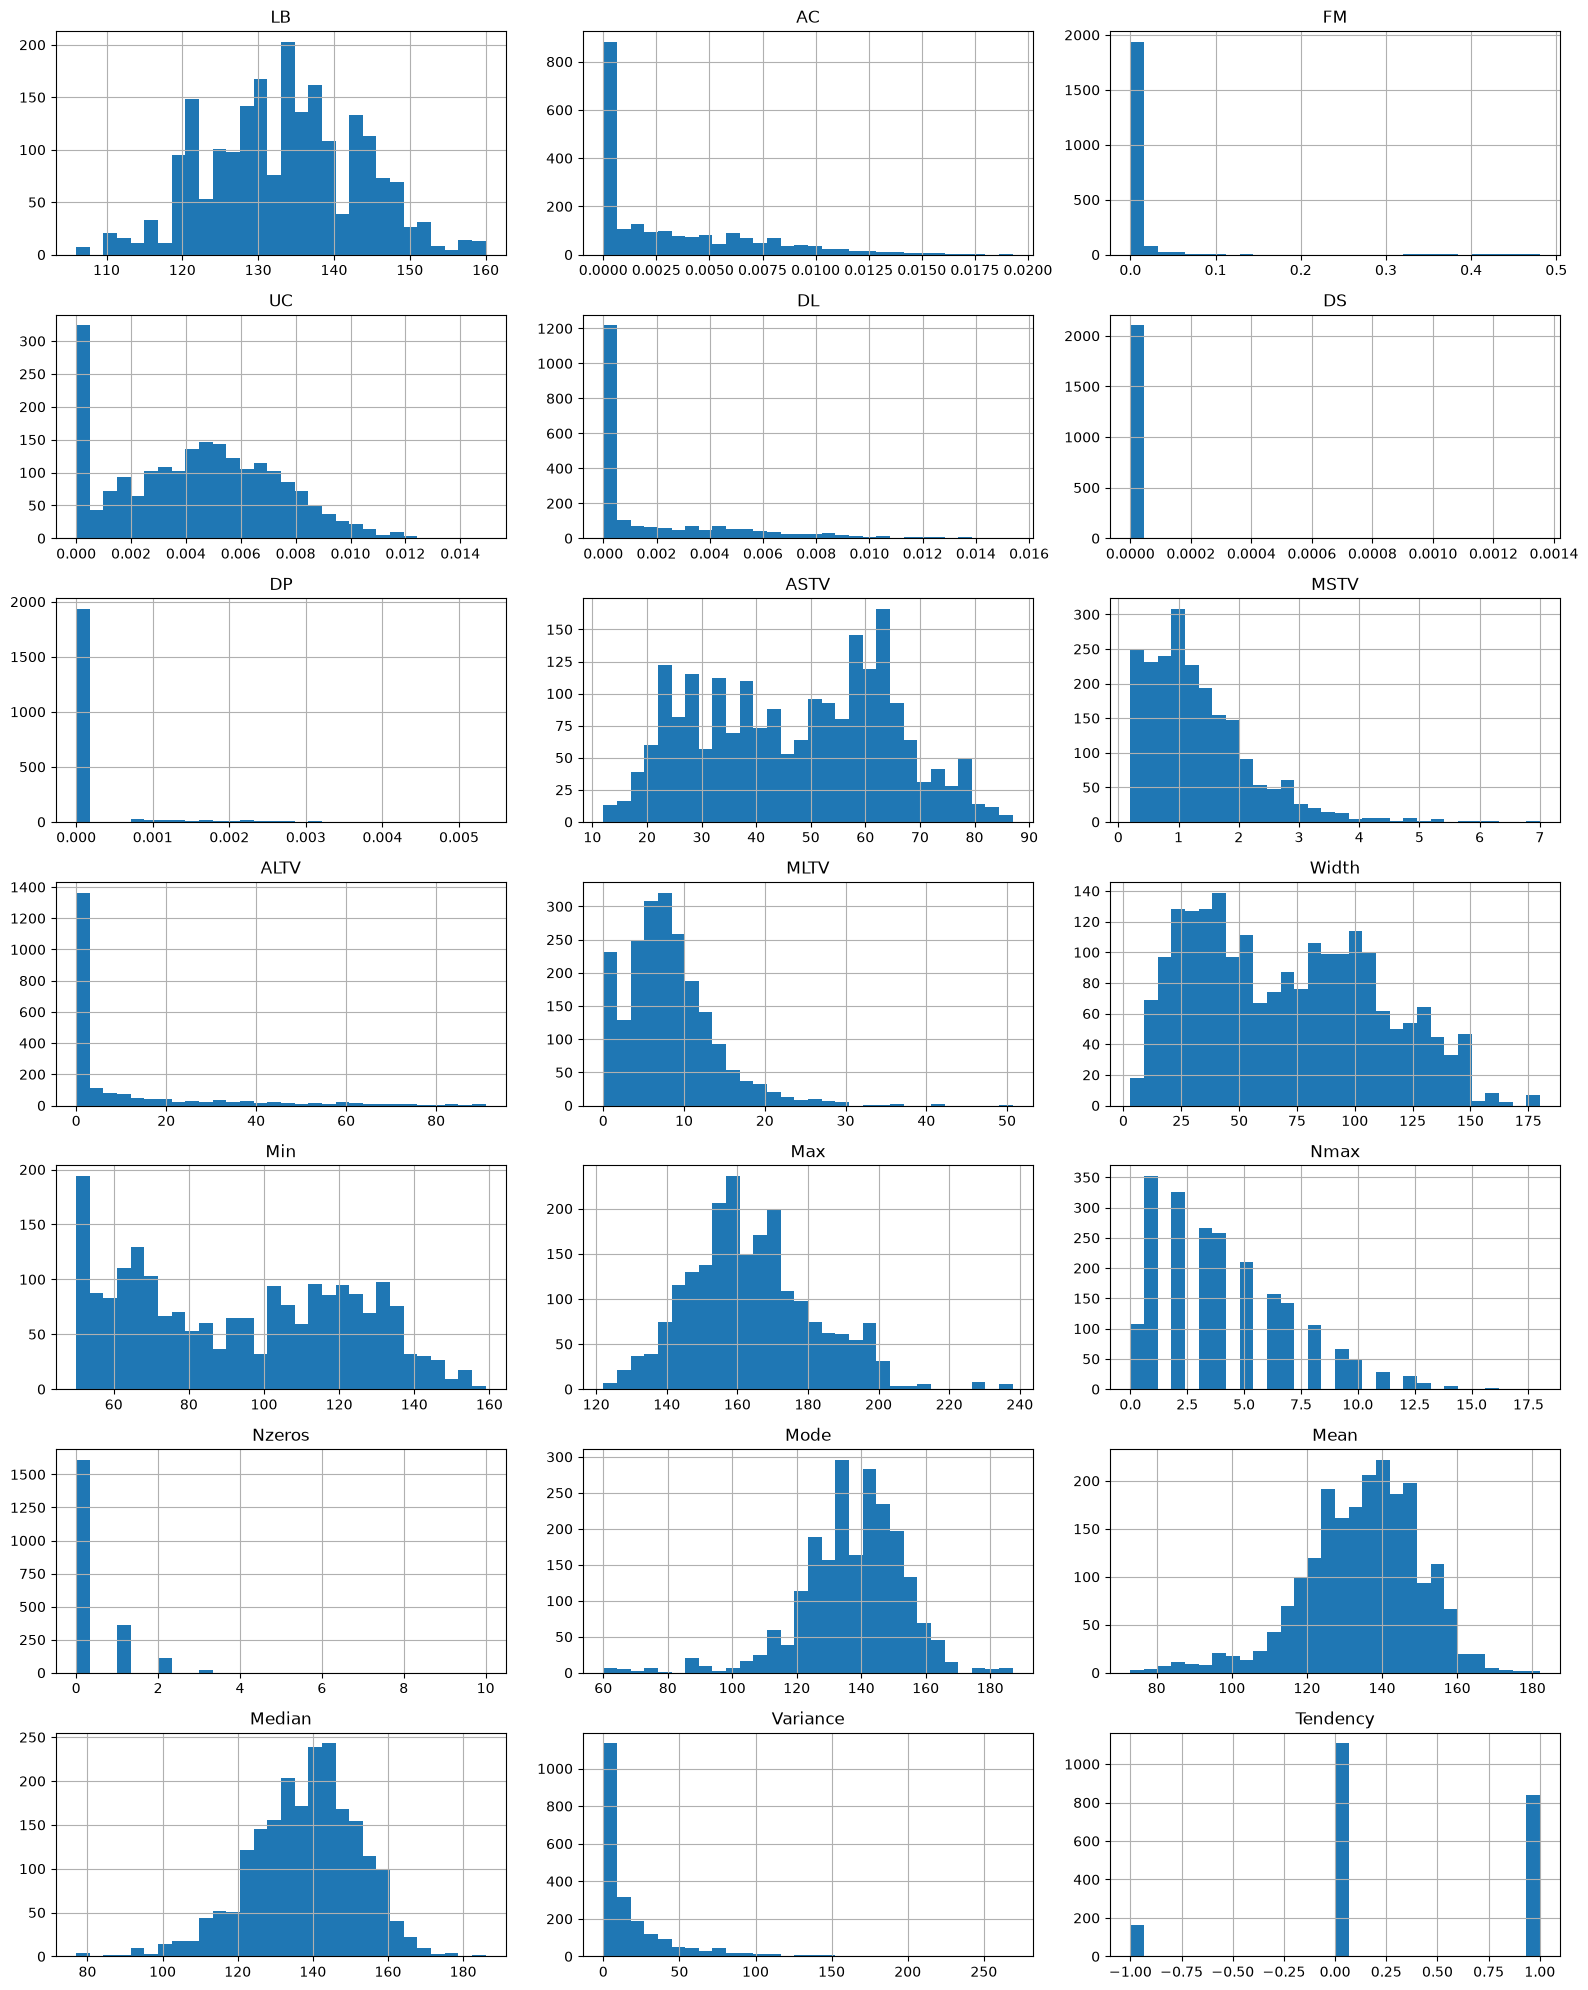

In [57]:
# Histograms of the 21 features

df_clean[features].hist(bins=30, figsize=(16, 20), layout=(7, 3))
plt.tight_layout()
plt.show()

The histograms show three main distribution patterns. Event-related features such as DS, DP, FM, DL and AC are concentrated at zero and have long right tails, which is consistent with many segments containing no recorded events. LB and ASTV are roughly symmetric, while Mode, Mean and Median show slight left skewness due to a small number of low values. These extreme values are real measurements rather than recording errors, so they will be kept.

In [59]:
# Skewness of each feature

skewness = df_clean[features].skew().round(2).sort_values(ascending=False)

skewness

DS          17.75
FM           7.78
DP           4.30
Nzeros       3.91
Variance     3.22
ALTV         2.21
DL           1.72
MSTV         1.66
MLTV         1.35
AC           1.20
Nmax         0.89
Max          0.58
Width        0.31
UC           0.15
Min          0.12
LB           0.02
ASTV        -0.01
Tendency    -0.31
Median      -0.48
Mean        -0.66
Mode        -1.00
dtype: float64

Ten of the 21 features have absolute skewness values above 1, with the highest values observed for DS (17.75), FM (7.78) and DP (4.3). This shows that several predictor variables have strongly non-symmetric distributions, which is also visible in the histograms.

#### 2.3 Selected predictors by foetal state

To identify which features differ across the three foetal states, a Kruskal-Wallis test was applied to each feature. Kruskal-Wallis compares several independent groups and uses ranks rather than the raw values, and does not require normally distributed data. This suits the dataset, as section 2.2 showed that many features are strongly skewed and the three classes are very different in size.

In [65]:
# Kruskal-Wallis test: does each feature differ across the three NSP groups?
kw_results = []

for feature in features:
    group_1 = df_clean.loc[df_clean['NSP'] == 1, feature]
    group_2 = df_clean.loc[df_clean['NSP'] == 2, feature]
    group_3 = df_clean.loc[df_clean['NSP'] == 3, feature]
    
    H_stat, p_value = kruskal(group_1, group_2, group_3)

    kw_results.append({
        'Feature': feature,
        'H Statistic': H_stat,
        'p-value': p_value
    })

kw_results = pd.DataFrame(kw_results)

kw_results = kw_results.sort_values(
    by='H Statistic',
    ascending=False
).reset_index(drop=True)

kw_results['Significant (p < 0.05)'] = kw_results['p-value'] < 0.05

kw_results

,Feature,H Statistic,p-value,Significant (p < 0.05)
0,DP,548.754068,6.911435e-120,True
1,ASTV,530.571544,6.135545e-116,True
2,ALTV,492.487635,1.142007e-107,True
3,AC,449.614472,2.330547e-98,True
4,MSTV,380.042936,2.983493e-83,True
5,Mean,304.410200,7.909788e-67,True
6,Median,295.458295,6.950985e-65,True
7,Mode,269.697942,2.727948e-59,True
8,LB,252.716091,1.328612e-55,True
9,Variance,229.489445,1.468927e-50,True


All 21 features show a statistically significant difference between the three classes (p<0.05), so the H statistic is used to compare their strength. DP, ASTV, ALTV, AC and MSTV have the largest H values, indicating that prolonged decelerations, abnormal variability and accelerations differ most between Normal, Suspect and Pathologic segments. Max, Nzeros and FM have the smallest H values and are the least useful for separating the classes.

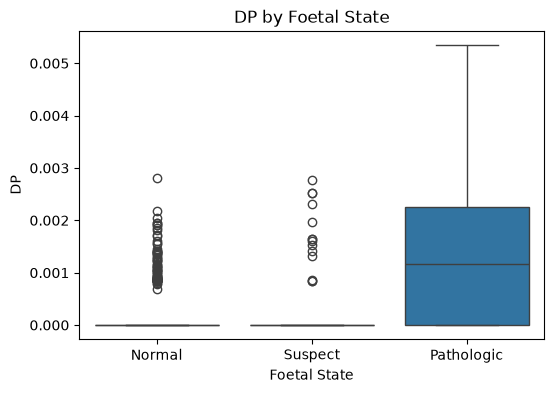

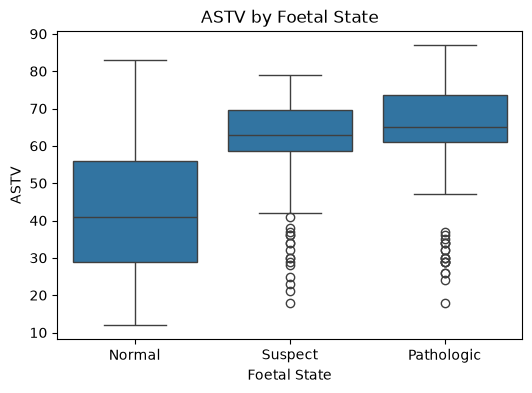

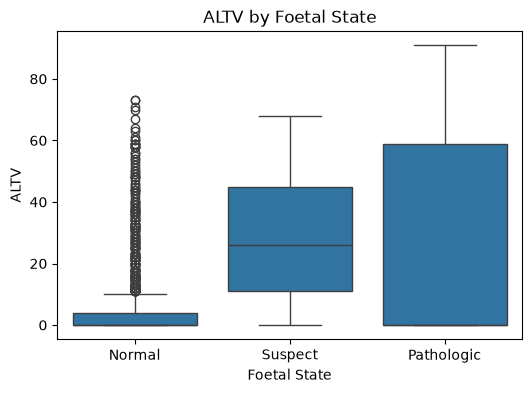

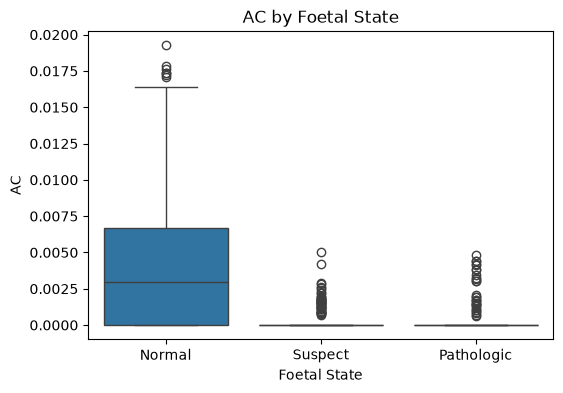

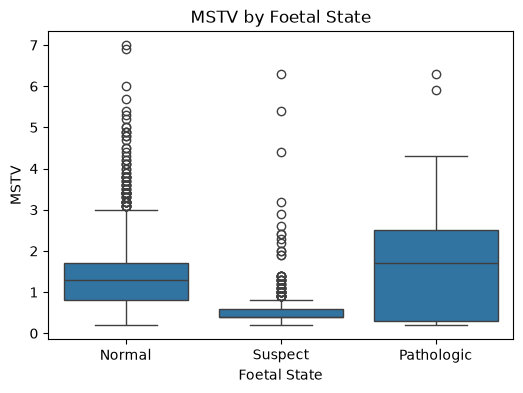

In [71]:
# Boxplots of selected features by foetal state

selected = kw_results['Feature'].head(5)

for feature in selected:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_clean, x='NSP', y=feature)
    plt.title(f'{feature} by Foetal State')
    plt.xlabel('Foetal State')
    plt.xticks([0, 1, 2], ['Normal', 'Suspect', 'Pathologic'])
    plt.show()


DP is mostly zero in Normal and Suspect segments but clearly higher in Pathologic segments, while AC is generally higher in Normal segments.

ASTV is higher in both Suspect and Pathologic segments than in Normal segments, and the two abnormal classes overlap widely.

MSTV is lowest in Suspect segments, while the Pathologic segment has a higher median and a wider distribution. 

This shows that predictor values do not consistently increase with severity. No single feature fully separates all three classes, and a combination of features is needed for classification.

#### 2.4 Correlation analysis

In [73]:
# Spearman correlation matrix

corr = df_clean[features].corr(method='spearman')
corr

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
LB,1.000000,-0.115584,-0.021415,-0.136103,-0.173432,-0.059989,-0.138263,0.314166,-0.364920,0.338508,...,-0.153743,0.355092,0.321911,-0.121331,-0.069069,0.816822,0.786446,0.839319,-0.237916,0.286254
AC,-0.115584,1.000000,0.047420,0.112326,-0.013344,-0.051439,-0.117099,-0.349191,0.328082,-0.492439,...,0.352469,-0.168899,0.468511,0.234485,0.001238,0.187143,0.210635,0.209545,0.392129,-0.020249
FM,-0.021415,0.047420,1.000000,-0.317087,0.032160,0.001453,0.124961,0.257646,0.072154,-0.077566,...,0.186275,-0.177204,0.116497,0.188243,-0.093922,-0.034208,-0.079817,-0.040704,0.114736,0.002613
UC,-0.136103,0.112326,-0.317087,1.000000,0.300391,0.006425,0.131721,-0.216990,0.324779,-0.282859,...,0.134580,-0.103075,0.103630,0.113863,0.057950,-0.091605,-0.174545,-0.138948,0.271487,-0.078773
DL,-0.173432,-0.013344,0.032160,0.300391,1.000000,0.062868,0.327269,-0.153743,0.619418,-0.385430,...,0.584748,-0.605261,0.233516,0.482705,0.278605,-0.251797,-0.471583,-0.330233,0.713223,0.073923
DS,-0.059989,-0.051439,0.001453,0.006425,0.062868,1.000000,0.038871,0.041311,0.052517,-0.046437,...,0.050849,-0.074639,-0.021986,0.015881,0.062500,-0.097850,-0.091678,-0.087386,0.091955,-0.054633
DP,-0.138263,-0.117099,0.124961,0.131721,0.327269,0.038871,1.000000,0.035678,0.300657,-0.217463,...,0.288735,-0.311154,0.109783,0.244144,0.082673,-0.311021,-0.403411,-0.357500,0.377908,-0.173007
ASTV,0.314166,-0.349191,0.257646,-0.216990,-0.153743,0.041311,0.035678,1.000000,-0.518358,0.421971,...,-0.281999,0.272055,-0.131012,-0.170123,-0.177065,0.121499,0.132525,0.159471,-0.343840,-0.004067
MSTV,-0.364920,0.328082,0.072154,0.324779,0.619418,0.052517,0.300657,-0.518358,1.000000,-0.683188,...,0.717481,-0.699313,0.376499,0.555833,0.299408,-0.310648,-0.457788,-0.356146,0.779489,-0.036705
ALTV,0.338508,-0.492439,-0.077566,-0.282859,-0.385430,-0.046437,-0.217463,0.421971,-0.683188,1.000000,...,-0.529243,0.469018,-0.323928,-0.361853,-0.168145,0.219739,0.289546,0.242699,-0.649319,0.067121


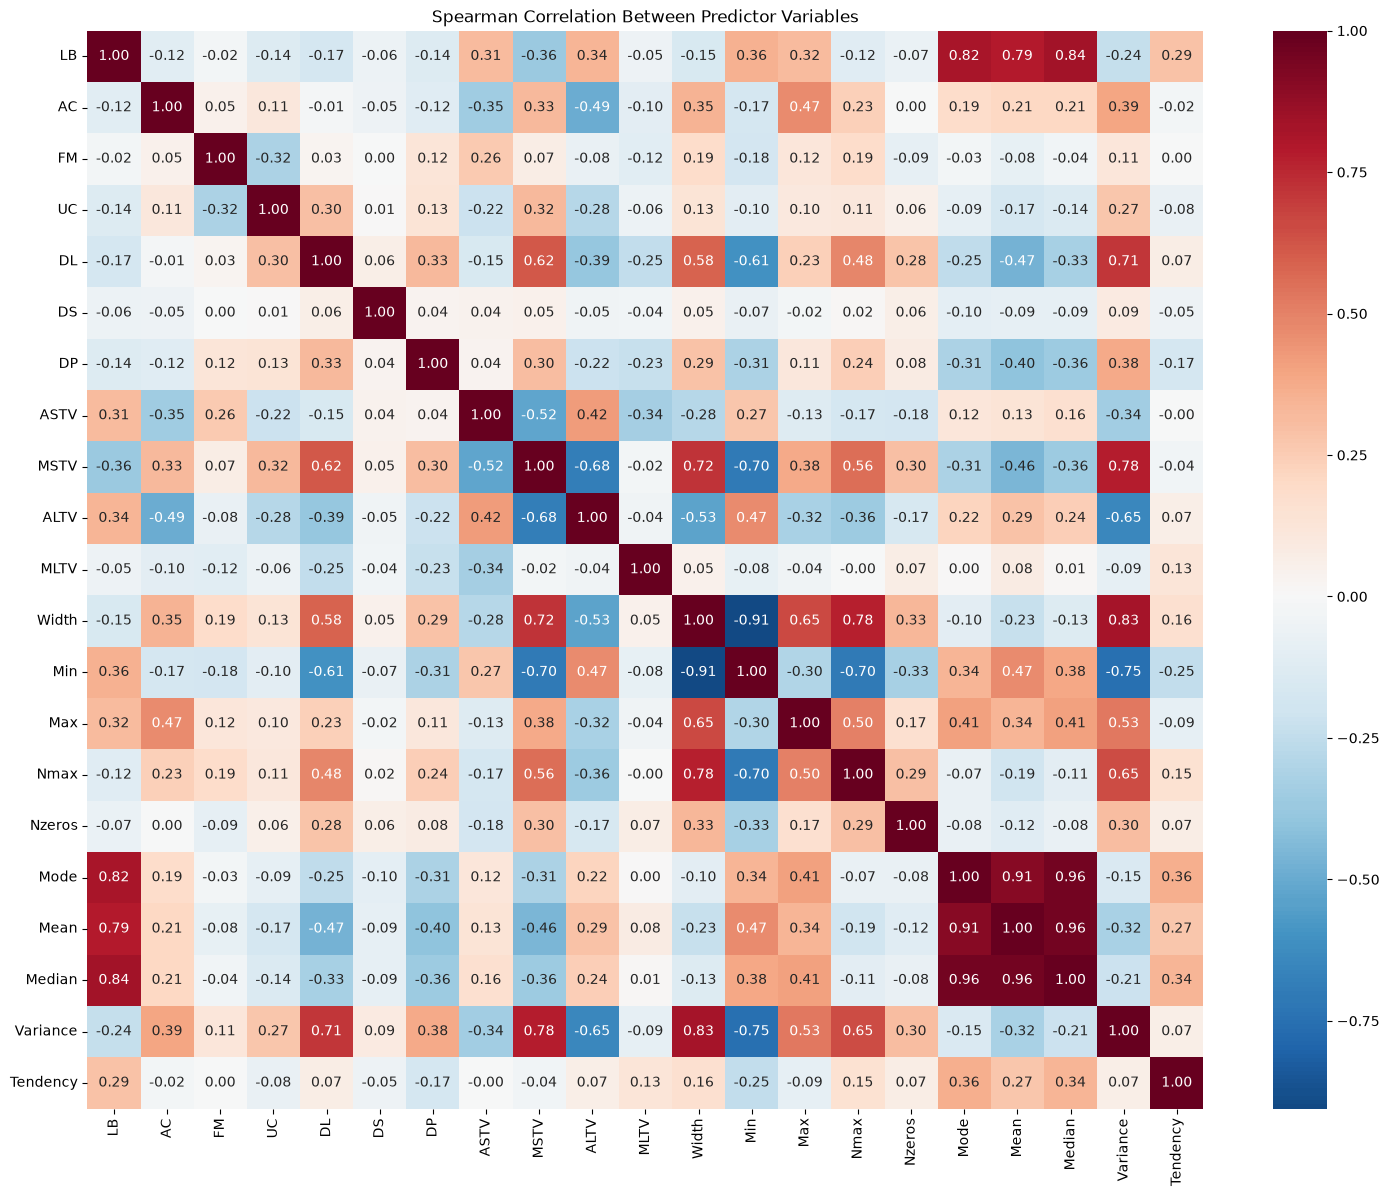

In [82]:
plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f')
plt.title('Spearman Correlation Between Predictor Variables')
plt.show()

Spearman correlation was used because many features are skewed. Strong correlations are visible among some related features. LB, Mode, Mean and Median are positively correlated (ρ = 0.79 to 0.96). Width is strongly negatively correlated with Min (ρ = -0.91) and positively correlated with Variance (ρ = 0.83). Other strong relationships are also present, such as MSTV with Variance (ρ = 0.78).

These correlations show that some predictors contain overlapping information, which should be considered when interpreting feature importance from the Random Forest model.

## 3. Model Development and Evaluation

#### 3.1 Model selection

Two tree-based classification models were selected: Decision Tree and Random Forest. This combination allows a comparison of how a single tree and an ensemble of trees perform on the training and test data, particularly in terms of overfitting and generalisation.

Decision Tree divides the data using feature thresholds and can capture non-linear relationships without requiring feature scaling or normally distributed predictors. This suits the dataset, as the features differ greatly in scale and many are strongly skewed (Section 2.2), and no single feature separates all three classes (Section 2.3). Its decision rules are easy to interpret, although a single tree can overfit the training data.

Random Forest combines predictions from multiple trees, each trained on a bootstrap sample with a random subset of features considered at each split. This can reduce overfitting and improve generalisation. Its feature importance scores will also be compared with the Kruskal-Wallis results.

Both models support class weighting to help address the imbalance identified in Section 2.1.

#### 3.2 Train-Test splits

The dataset will be split into training and test sets using three test sizes: 5%, 15% and 25%, to examine how the size of the test set affects model performance. As the target variable is imbalanced, stratified splitting will be used to maintain similar class proportions in each split. The same random state will be used to make the results reproducible.

In [97]:
test_sizes = [0.05, 0.15, 0.25]

splits = {}

for size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=size,
        random_state=123,
        stratify=y
    )
    splits[size] = (X_train, X_test, y_train, y_test)
    print(size, X_train.shape, X_test.shape)

0.05 (2005, 21) (106, 21)
0.15 (1794, 21) (317, 21)
0.25 (1583, 21) (528, 21)


#### 3.3 Model training and cross-validation

Decision Tree and Random Forest will be evaluated on the training data from each of the three train-test splits. Five-fold cross-validation will be used to calculate the mean accuracy for each model. 

In [142]:
# Define two models

dt = DecisionTreeClassifier(random_state=123, class_weight='balanced')
rf = RandomForestClassifier(random_state=123, class_weight='balanced')

In [101]:
results = []

for size in test_sizes:
    (X_train, X_test, y_train, y_test) = splits[size]

    for name, model in [('Decision Tree', dt), ('Random Forest', rf)]:
        
        # 5-fold cross-validation
        cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=5,
        scoring='accuracy'
        )

        # Train the model
        model.fit(X_train, y_train)

        # Evaluate on both training and test sets
        train_acc = model.score(X_train, y_train)
        test_acc = model.score(X_test, y_test)
        
        results.append([
            size, name,
            cv_scores.mean(),
            cv_scores.std(),
            train_acc,
            test_acc
        ])

In [102]:

cv_results = pd.DataFrame(
    results,
    columns=['Test Size', 'Model', 'CV Mean Accuracy', 'CV Std', 'Train Accuracy', 'Test Accuracy']
).round(3)

cv_results

,Test Size,Model,CV Mean Accuracy,CV Std,Train Accuracy,Test Accuracy
0,0.05,Decision Tree,0.925,0.010,1.000,0.877
1,0.05,Random Forest,0.938,0.011,0.992,0.906
2,0.15,Decision Tree,0.920,0.019,1.000,0.915
3,0.15,Random Forest,0.943,0.004,0.989,0.902
4,0.25,Decision Tree,0.918,0.014,1.000,0.928
5,0.25,Random Forest,0.939,0.018,0.992,0.936


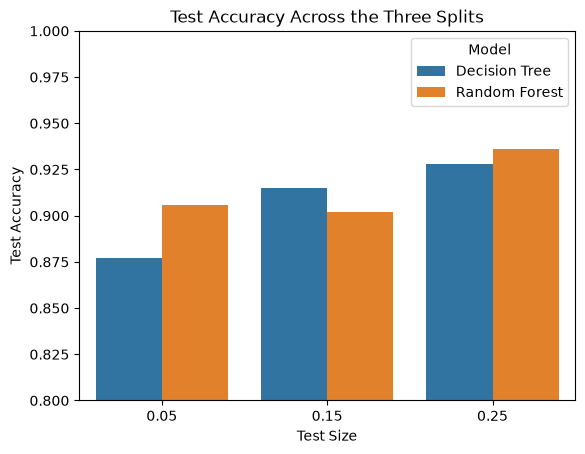

In [103]:
sns.barplot(data=cv_results, x='Test Size', y='Test Accuracy', hue='Model')
plt.ylim(0.8, 1.0)
plt.title('Test Accuracy Across the Three Splits')
plt.show()

The Decision Tree reached 100% training accuracy in all three splits, and its cross-validation accuracy was about 92%, shows overfitting. Random Forest performed better in cross-validation for every split, with accuracy ranging from 0.938 to 0.943 and smaller gaps between training and validation performance. These results suggest better generalisation.

Test accuracy varied across splits, particularly when the test set contained only 5% of the data, or 106 samples. With the 15% test split, Decision Tree slightly outperformed Random Forest on the test set despite its lower cross-validation accuracy. This difference illustrates the sensitivity of a single test result to the selected samples and supports using cross-validation for model comparison. The split with 25% of the data reserved for testing was selected for the subsequent hyperparameter-tuning stage because it provided the largest test set.

#### 3.4 Hyperparameter tuning

Hyperparameter tuning will adjust model complexity, including tree depth and the minimum number of samples per leaf, to balance underfitting and overfitting. GridSearchCV will evaluate parameter combinations using five-fold cross-validation on the training data from the 25% test split. This split provides the largest independent test set for evaluating the tuned models. Macro F1 will be used as the scoring metric because it gives equal weight to each class despite the imbalance in class sizes.

In [106]:
# Use the 25% split for tuning
X_train, X_test, y_train, y_test = splits[0.25]

# Define the parameter values to try for each model
param_grids = {
    'Decision Tree': {
        'criterion': ['gini', 'entropy'],
        'max_depth': [None, 5, 10, 15],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2']
    }
}

models = {'Decision Tree': dt, 'Random Forest': rf}

In [108]:
tuning_results = []
best_models = {}

for name, model in models.items():

    # Run GridSearchCV with 5-fold cross-validation and macro F1 as the score
    grid_search = GridSearchCV(model, param_grids[name], cv=5, scoring='f1_macro', n_jobs=-1)
    grid_search.fit(X_train, y_train)

    # Keep the best model (refitted on the full training set)
    best_model = grid_search.best_estimator_
    best_models[name] = best_model

    # Evaluate the best model on the training and test sets
    y_pred = best_model.predict(X_test)

    tuning_results.append([
        name,
        grid_search.best_params_,
        grid_search.best_score_,
        best_model.score(X_train, y_train),
        best_model.score(X_test, y_test),
        f1_score(y_test, y_pred, average='macro')
    ])


In [112]:
# Summarise the results in a table

tuning_df = pd.DataFrame(tuning_results, columns=[
    'Model', 'Best Parameters', 'Best CV Macro F1',
    'Train Accuracy', 'Test Accuracy', 'Test Macro F1'
]).round(3)

pd.set_option('display.max_colwidth', None)

tuning_df

,Model,Best Parameters,Best CV Macro F1,Train Accuracy,Test Accuracy,Test Macro F1
0,Decision Tree,"{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5}",0.870,0.980,0.922,0.887
1,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}",0.891,0.992,0.936,0.902


Hyperparameter tuning produced no improvement in test performance. The selected Decision Tree used the entropy criterion and maximum depth of 10. Training accuracy decreased from 1.000 to 0.980, while test accuracy fell slightly from 0.928 to 0.922. This suggests less overfitting.

For Random Forest, the selected parameters matched the default settings, leaving test accuracy at 0.936 and macro F1 at 0.902. Random Forest continued to outperform Decision Tree after tuning, shows that model choice has a greater effect on performance than the parameter combinations tested in this analysis.

#### 3.5 Model evaluation

The tuned Decision Tree and Random Forest models will be evaluated on the 25% test set using precision, recall and F1-score for each class. Confusion matrices will show how the models classify Normal, Suspect and Pathologic cases. These measures are important because overall accuracy may hide weaker performance on the minority classes. Particular attention will be given to Pathologic recall because failing to identify these cases could have serious clinical consequences.

In [114]:
# Generate predictions:

class_names = ['Normal', 'Suspect', 'Pathologic']

## Tuned models from section 3.4
dt_best = best_models['Decision Tree']
rf_best = best_models['Random Forest']

# Predict the 25% test set
dt_pred = dt_best.predict(X_test)
rf_pred = rf_best.predict(X_test)

In [124]:
# Classification reports

print('Decision Tree')
print(classification_report(
    y_test,
    dt_pred,
    target_names=['Normal', 'Suspect', 'Pathologic']
))

print('Random Forest')
print(classification_report(
    y_test,
    rf_pred,
    target_names=['Normal', 'Suspect', 'Pathologic']
))

Decision Tree
              precision    recall  f1-score   support

      Normal       0.96      0.94      0.95       411
     Suspect       0.73      0.81      0.77        73
  Pathologic       0.93      0.95      0.94        44

    accuracy                           0.92       528
   macro avg       0.87      0.90      0.89       528
weighted avg       0.93      0.92      0.92       528

Random Forest
              precision    recall  f1-score   support

      Normal       0.97      0.95      0.96       411
     Suspect       0.74      0.85      0.79        73
  Pathologic       0.95      0.95      0.95        44

    accuracy                           0.94       528
   macro avg       0.89      0.92      0.90       528
weighted avg       0.94      0.94      0.94       528



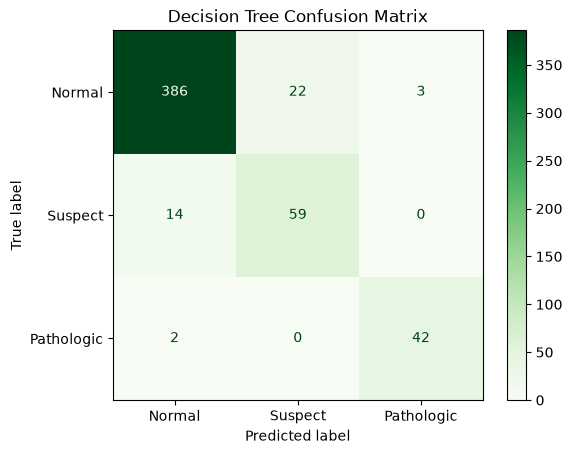

In [121]:
# Confusion matrix for Decision Tree

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=['Normal', 'Suspect', 'Pathologic'],
    cmap='Greens'
)

plt.title('Decision Tree Confusion Matrix')
plt.show()

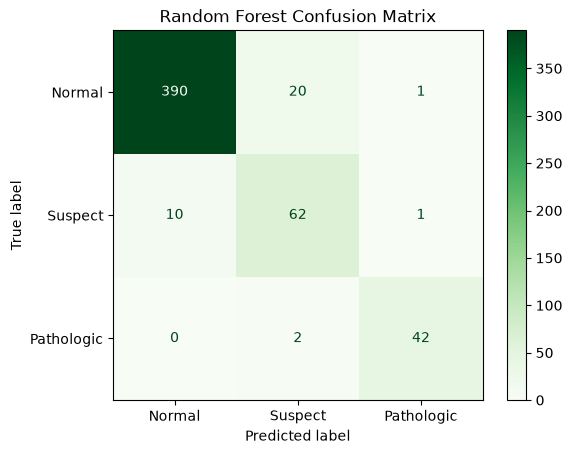

In [123]:
# Confusion matrix for Random Forest

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=['Normal', 'Suspect', 'Pathologic'],
    cmap='Greens'
)

plt.title('Random Forest Confusion Matrix')
plt.show()

Random Forest classified 494 of the 528 cases in the 25% test set correctly, compared with 487 for Decision Tree. Suspect was the most difficult class for both models, with F1 scores of 0.77 for Decision Tree and 0.79 for Random Forest. Most errors involved confusion between Normal and Suspect cases.

Both models accurately identified 42 of the 44 Pathologic cases. Random Forest performed better on the Normal and Suspect classes and classified no Pathologic cases as Normal. Together with its higher test accuracy and macro F1, these results indicate better overall performance on this test set.

#### 3.6 Feature importance

Random Forest feature importance shows how much each feature helps the trees split the data into classes, with scores normalised to sum to one. The scores from the tuned model will be examined to identify the predictors that contribute most to its classification decisions. They will then be compared with the Kruskal-Wallis results in Section 2.3 to assess whether features with greater differences across foetal-state classes also receive higher importance scores. 

In [141]:
rf_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_best.feature_importances_
})

# Sort by importance and add a rank
rf_importance = rf_importance.sort_values('Importance', ascending=False).reset_index(drop=True)
rf_importance['RF Rank'] = range(1, len(rf_importance) + 1)
rf_importance.round(3)

,Feature,Importance,RF Rank
0,ASTV,0.120,1
1,ALTV,0.115,2
2,AC,0.108,3
3,Mean,0.104,4
4,Median,0.080,5
5,Mode,0.069,6
6,MLTV,0.067,7
7,MSTV,0.053,8
8,LB,0.043,9
9,DP,0.041,10


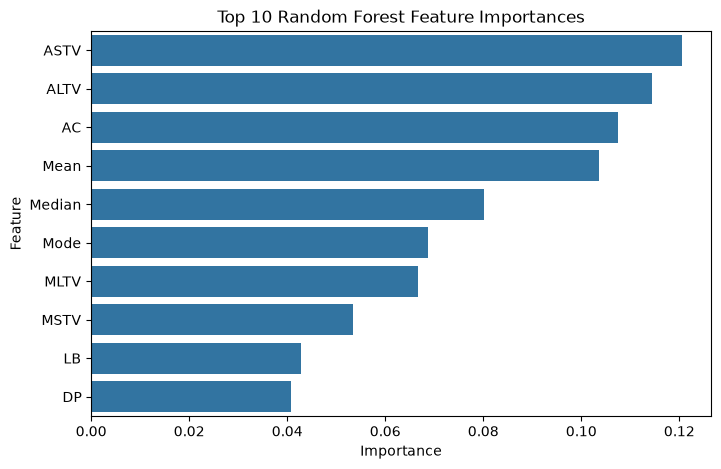

In [135]:
# Plot of top 10 features

top10 = rf_importance.head(10)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=top10,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Random Forest Feature Importances')
plt.show()

In [138]:
# Compare with the Kruskal-Wallis ranking from section 2.3

kw_rank = kw_results[['Feature', 'H Statistic']].copy()
kw_rank['KW Rank'] = range(1, len(kw_rank) + 1)

comparison = rf_importance.merge(kw_rank, on='Feature')
comparison[['Feature', 'Importance', 'RF Rank', 'H Statistic', 'KW Rank']].round(3)

,Feature,Importance,RF Rank,H Statistic,KW Rank
0,ASTV,0.120,1,530.572,2
1,ALTV,0.115,2,492.488,3
2,AC,0.108,3,449.614,4
3,Mean,0.104,4,304.410,6
4,Median,0.080,5,295.458,7
5,Mode,0.069,6,269.698,8
6,MLTV,0.067,7,165.352,12
7,MSTV,0.053,8,380.043,5
8,LB,0.043,9,252.716,9
9,DP,0.041,10,548.754,1


ASTV, ALTV and AC had the highest Random Forest importance scores and were also among the top four features in the Kruskal-Wallis test. Nzeros, DS and FM had both low H statistics and low importance scores. The two rankings showed broadly similar patterns.

DP was the main exception, ranking first in the Kruskal-Wallis test but tenth in Random Forest importance. It is zero in most segments and mainly distinguishes Pathologic cases, which may help explain its lower importance when considered alongside other predictors. Mean, Median and Mode ranked fourth, fifth and sixth individually, and their combined importance was about 0.25. As these features were strongly correlated in Section 2.4, their predictive contribution may be shared across the three variables in the Random Forest model.

## 4. Summary

This study compared Decision Tree and Random Forest for classifying foetal state from CTG data. Decision Tree showed overfitting, achieving 100% training accuracy but lower cross-validation and test scores. Random Forest achieved higher cross-validation accuracy across all three splits and reached a test accuracy of 0.936 and macro F1 of 0.902 on the 25% test set. Tuning reduced Decision Tree training accuracy but did not improve test performance. Suspect remained the most difficult class to classify, while recall for Pathologic cases was high.

Random Forest feature importance broadly agreed with the Kruskal-Wallis ranking, ASTV, ALTV and AC were among the highest-ranked predictors in both analyses.

Segments from the same recording may have appeared in both training and test sets, potentially overestimating performance on unseen recordings. The data also came from a single source and included relatively few Pathologic cases. Future work could keep segments from the same recording together when splitting the data, compare other classification methods, and evaluate performance on external CTG datasets.